In [ ]:
# you can find a live solution at: https://www.kaggle.com/code/sndorburian/nisar-demo

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import kagglehub


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [32]:
!pip install asf-search

In [33]:
!pip install rasterio

In [34]:
import asf_search as asf

results = asf.granule_search(['ALPSRS279162400', 'ALPSRS279162200'])
#print(results)

wkt = 'POLYGON((-135.7 58.2,-136.6 58.1,-135.8 56.9,-134.6 56.1,-134.9 58.0,-135.7 58.2))'
results = asf.geo_search(platform=[asf.PLATFORM.SENTINEL1], intersectsWith=wkt, maxResults=10)
#print(results)

In [35]:
import asf_search as asf

# 1. Keresési terület (Bounding Box / WKT) megadása - pl. egy magyarországi tesztterület
aoi_wkt = "POLYGON((19.0 47.4, 19.2 47.4, 19.2 47.5, 19.0 47.5, 19.0 47.4))"

# 2. Lekérdezés: NISAR L2 GCOV vagy OPERA RTC-S1
results = asf.search(
    dataset=[asf.DATASET.NISAR, asf.DATASET.OPERA_S1],
    processingLevel=[asf.PRODUCT_TYPE.GCOV, asf.PRODUCT_TYPE.RTC],
    intersectsWith=aoi_wkt,
    start="2026-07-01",
    end="2026-11-14",
    maxResults=5
)

for item in results:
    print(item.properties['sceneName'], item.properties['url'])

NISAR_L2_PR_GCOV_034_057_A_026_2005_DHDH_A_20261028T032941_20261028T033016_P05036_N_F_J_001 https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_034_057_A_026_2005_DHDH_A_20261028T032941_20261028T033016_P05036_N_F_J_001/NISAR_L2_PR_GCOV_034_057_A_026_2005_DHDH_A_20261028T032941_20261028T033016_P05036_N_F_J_001.h5
NISAR_L2_PR_GCOV_034_051_D_065_2005_DHDH_A_20261027T175247_20261027T175322_P05036_N_F_J_001 https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_034_051_D_065_2005_DHDH_A_20261027T175247_20261027T175322_P05036_N_F_J_001/NISAR_L2_PR_GCOV_034_051_D_065_2005_DHDH_A_20261027T175247_20261027T175322_P05036_N_F_J_001.h5
NISAR_L2_PR_GCOV_034_051_D_064_2005_DHDH_A_20261027T175212_20261027T175248_P05036_N_F_J_001 https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_034_051_D_064_2005_DHDH_A_20261027T175212_20261027T175248_P05036_N_F_J_001/NISAR_L2_PR_GCOV_034_051_D_064_2005_DHDH_A_20261027T175212_2026

In [ ]:
import os

# Never hard-code tokens; set EARTHDATA_TOKEN in the environment.
earthdata_token = os.environ["EARTHDATA_TOKEN"]

In [39]:
import asf_search as asf
from getpass import getpass
from importlib.metadata import version

token = getpass("Earthdata token: ").strip()
session = asf.ASFSession()

url = (
    f"https://{session.edl_host}/oauth/tokens/user"
    f"?client_id={session.edl_client_id}"
)

response = session.post(
    url,
    data={"token": token},
    timeout=30,
)

print("asf-search verzió:", version("asf-search"))
print("HTTP-státusz:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))

# A token esetleges visszatükrözését eltávolítjuk a kiírásból.
safe_body = response.text.replace(token, "[TOKEN ELREJTVE]") if token else ""
print("Szerverválasz első 1000 karaktere:")
print(safe_body[:1000])

Earthdata token:  ········


asf-search verzió: 14.1.0
HTTP-státusz: 200
Content-Type: application/json; charset=utf-8
Szerverválasz első 1000 karaktere:
{"uid":"sandor95"}


In [40]:
from pathlib import Path
import asf_search as asf
import rasterio

session = asf.ASFSession().auth_with_token(earthdata_token)

url = vv_cog_url.strip()
target = Path("/kaggle/working/opera_vv_test.tif")

tiff_signatures = (
    b"II\x2a\x00",  # TIFF, little endian
    b"MM\x00\x2a",  # TIFF, big endian
    b"II\x2b\x00",  # BigTIFF, little endian
    b"MM\x00\x2b",  # BigTIFF, big endian
)

with session.get(url, stream=True, timeout=(30, 180)) as response:
    print("HTTP-státusz:", response.status_code)
    print("Content-Type:", response.headers.get("Content-Type"))
    print("Végső kiszolgáló:", response.url.split("/")[2])
    response.raise_for_status()

    chunks = response.iter_content(chunk_size=1024 * 1024)
    first_chunk = next((chunk for chunk in chunks if chunk), b"")

    if not first_chunk.startswith(tiff_signatures):
        raise RuntimeError(
            "A szerver válasza nem TIFF/BigTIFF. "
            "Ellenőrizd az Earthdata-hitelesítést és a letöltési URL-t."
        )

    with target.open("wb") as output:
        output.write(first_chunk)
        for chunk in chunks:
            if chunk:
                output.write(chunk)

with rasterio.open(target) as src:
    print("Driver:", src.driver)
    print("Méret:", src.width, src.height)
    print("Vetület:", src.crs)

HTTP-státusz: 200
Content-Type: binary/octet-stream
Végső kiszolgáló: d1bctmng8vmwga.cloudfront.net
Driver: GTiff
Méret: 3435 1488
Vetület: EPSG:32634


In [45]:
import numpy as np

# Szimulálunk egy 256x256 pixeles csempét valósághű lineáris gamma-0 (szám)értékekkel:
# Ko-polarizált (HH vagy VV) általában 0.05 és 0.5 között mozog
gamma0_co = np.random.uniform(0.05, 0.4, size=(256, 256)).astype("float32")

# Keresztpolarizált (HV vagy VH) általában kisebb, 0.005 és 0.1 között mozog
gamma0_cross = np.random.uniform(0.005, 0.08, size=(256, 256)).astype("float32")

eps = 1e-10  # Nullával való osztás elkerülésére

# --- INNENTŐL A TE KÓDOD VÁLTOZATLANUL MŰKÖDIK ---

# 1. Radar Vegetation Index (RVI) - Általános növényi sűrűség és struktúra (0-tól ~1-ig)
rvi_tile = (4.0 * gamma0_cross) / (gamma0_co + gamma0_cross + eps)

# 2. Keresztpolarizációs arány (Cross-pol Ratio)
ratio_tile = gamma0_cross / (gamma0_co + eps)

# 3. HV / VH decibelben (dB) - Felszín feletti biomassza (AGB) becsléshez
biomass_proxy_db = 10.0 * np.log10(np.clip(gamma0_cross, eps, None))

print("RVI csempe átlaga:", np.nanmean(rvi_tile))
print("Biomassza (dB) csempe átlaga:", np.nanmean(biomass_proxy_db))

RVI csempe átlaga: 0.72990686
Biomassza (dB) csempe átlaga: -14.49688


In [48]:
from pathlib import Path
from urllib.parse import urlsplit
import rasterio

url = vv_cog_url.strip()

if not url.startswith("https://") or any(c in url for c in "[]\r\n"):
    raise ValueError(
        "A vv_cog_url változóban nyers HTTPS URL legyen, "
        "ne Markdown-hivatkozás vagy /vsicurl/ elérési út."
    )

target = Path("/kaggle/working/opera_vv_test.tif")
partial = target.with_suffix(".tif.part")

tiff_signatures = (
    b"II\x2a\x00",
    b"MM\x00\x2a",
    b"II\x2b\x00",
    b"MM\x00\x2b",
)

try:
    with session.get(url, stream=True, timeout=(30, 180)) as response:
        print("HTTP-státusz:", response.status_code)
        print("Content-Type:", response.headers.get("Content-Type"))
        print("Végső kiszolgáló:", urlsplit(response.url).hostname)

        response.raise_for_status()

        chunks = response.iter_content(chunk_size=1024 * 1024)
        first = next((chunk for chunk in chunks if chunk), b"")

        print("Első 8 bájt:", repr(first[:8]))

        if not first.startswith(tiff_signatures):
            raise RuntimeError(
                "A válasz nem TIFF/BigTIFF. "
                "Lehet bejelentkezési oldal vagy szerveroldali hibaüzenet."
            )

        with partial.open("wb") as output:
            output.write(first)
            for chunk in chunks:
                if chunk:
                    output.write(chunk)

    partial.replace(target)

except Exception:
    partial.unlink(missing_ok=True)
    raise

with rasterio.open(target) as src:
    print("Sikeres helyi megnyitás")
    print("Driver:", src.driver)
    print("Méret:", src.width, src.height)
    print("CRS:", src.crs)
    print("Sávok száma:", src.count)

HTTP-státusz: 200
Content-Type: binary/octet-stream
Végső kiszolgáló: d1bctmng8vmwga.cloudfront.net
Első 8 bájt: b'II*\x00\xc0\x00\x00\x00'
Sikeres helyi megnyitás
Driver: GTiff
Méret: 3435 1488
CRS: EPSG:32634
Sávok száma: 1


In [51]:
from pathlib import Path

vh_path = Path("/kaggle/working/opera_vh_test.tif")
partial = vh_path.with_suffix(".tif.part")

tiff_signatures = (
    b"II\x2a\x00", b"MM\x00\x2a",
    b"II\x2b\x00", b"MM\x00\x2b",
)

try:
    with session.get(
        vh_cog_url.strip(), stream=True, timeout=(30, 180)
    ) as response:
        print("VH HTTP-státusz:", response.status_code)
        response.raise_for_status()

        chunks = response.iter_content(chunk_size=1024 * 1024)
        first = next((chunk for chunk in chunks if chunk), b"")

        if not first.startswith(tiff_signatures):
            raise RuntimeError(
                "A VH letöltési válasz nem TIFF/BigTIFF."
            )

        with partial.open("wb") as output:
            output.write(first)
            for chunk in chunks:
                if chunk:
                    output.write(chunk)

    partial.replace(vh_path)

except Exception:
    partial.unlink(missing_ok=True)
    raise

print("VH letöltve:", vh_path.stat().st_size, "bájt")

VH HTTP-státusz: 200
VH letöltve: 7364042 bájt


In [52]:
import rasterio
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds, Window
from rasterio.errors import WindowError

vv_path = "/kaggle/working/opera_vv_test.tif"
vh_path = "/kaggle/working/opera_vh_test.tif"

with rasterio.open(vv_path) as src_vv:
    print("VV megnyitva.")

    with rasterio.open(vh_path) as src_vh:
        print("VH megnyitva.")

        same_grid = (
            src_vv.crs == src_vh.crs
            and src_vv.transform == src_vh.transform
            and src_vv.width == src_vh.width
            and src_vv.height == src_vh.height
        )

        if not same_grid:
            raise ValueError(
                "A VV és VH raszterek pixelrácsa eltér. "
                "Közös rácsra illesztés szükséges."
            )

        # bbox_wgs84 sorrendje:
        # (min_lon, min_lat, max_lon, max_lat)
        projected_bounds = transform_bounds(
            "EPSG:4326",
            src_vv.crs,
            *bbox_wgs84,
            densify_pts=21,
        )

        window = from_bounds(
            *projected_bounds,
            transform=src_vv.transform,
        )

        # Csak a raszterrel közös területet olvassuk.
        full_window = Window(0, 0, src_vv.width, src_vv.height)

        try:
            window = window.intersection(full_window)
        except WindowError as exc:
            raise ValueError(
                "A megadott bbox nem metszi a kiválasztott képet."
            ) from exc

        gamma0_vv = src_vv.read(
            1, window=window, masked=True
        ).astype("float32")

        gamma0_vh = src_vh.read(
            1, window=window, masked=True
        ).astype("float32")

        tile_transform = src_vv.window_transform(window)
        tile_crs = src_vv.crs

print("VV kivágás:", gamma0_vv.shape)
print("VH kivágás:", gamma0_vh.shape)

# Innen folytatható az RVI számítása.
eps = 1e-10

VV megnyitva.
VH megnyitva.
VV kivágás: (113, 78)
VH kivágás: (113, 78)


In [53]:
!pip install titiler.application uvicorn

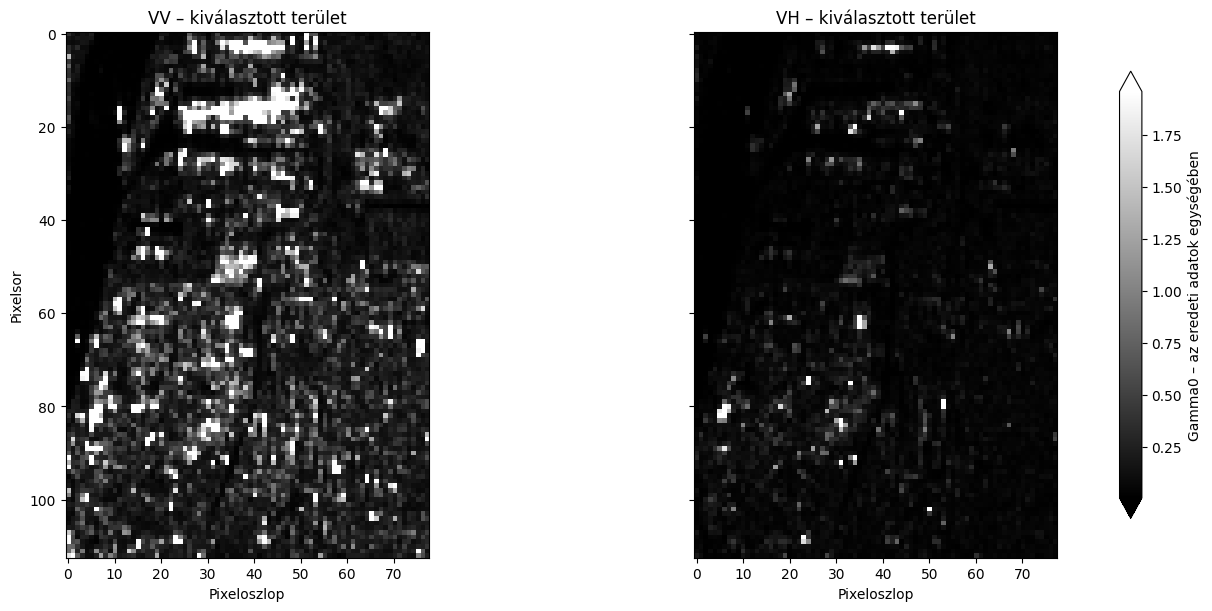

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# A meglévő maszkok megőrzése, NaN/Inf értékek maszkolása.
vv = np.ma.masked_invalid(
    np.ma.asarray(gamma0_vv, dtype="float32")
)
vh = np.ma.masked_invalid(
    np.ma.asarray(gamma0_vh, dtype="float32")
)

if vv.count() == 0 or vh.count() == 0:
    raise ValueError("Az egyik kivágás nem tartalmaz érvényes pixelt.")

# Mintavétel csak a megjelenítési határok meghatározásához.
samples = np.concatenate([
    vv.compressed()[::10],
    vh.compressed()[::10],
])

vmin, vmax = np.percentile(samples, [2, 98])
if vmax <= vmin:
    vmax = vmin + max(abs(float(vmin)) * 0.01, 1e-6)

cmap = plt.get_cmap("gray").copy()
cmap.set_bad("lightgray")

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, data, title in zip(
    axes,
    [vv, vh],
    ["VV – kiválasztott terület", "VH – kiválasztott terület"],
):
    image = ax.imshow(
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        origin="upper",
        interpolation="nearest",
    )
    ax.set_title(title)
    ax.set_xlabel("Pixeloszlop")

axes[0].set_ylabel("Pixelsor")

fig.colorbar(
    image,
    ax=axes,
    label="Gamma0 – az eredeti adatok egységében",
    shrink=0.85,
    extend="both",
)

plt.show()

A világosszürke területek a maszkolt, érvénytelen pixeleket jelölik. A színskála levágása csak a megjelenítésre vonatkozik, a gamma0_vv és gamma0_vh eredeti értékeit nem módosítja.

számoljuk ki az RVI-t a már beolvasott gamma0_vv és gamma0_vh tömbökből, majd rögtön jelenítsük meg.

Az egyszerű, kétpolarizációs RVI-közelítést használjuk:

$$
\mathrm{RVI} =
\frac{4\,\gamma^{0}_{VH}}
{\gamma^{0}_{VV}+\gamma^{0}_{VH}}
$$
 
Ez egy VV–VH alapú közelítés, nem azonos a teljes polarimetrikus RVI-vel vagy a DpRVI más változataival. Ez egy VV–VH alapú közelítés, nem azonos a teljes polarimetrikus RVI-vel vagy a DpRVI más változataival.

A képletbe lineáris intenzitásértékek kellenek, nem dB-értékek. Az alábbi cellában az INPUT_IS_DB = False beállítást használd, ha az eredeti lineáris gamma0-adatokat olvastad be, és azóta nem alakítottad őket dB-be.



Érvényes pixelek: 8814
RVI minimum: 0.010
RVI medián:  0.743
RVI maximum: 3.218


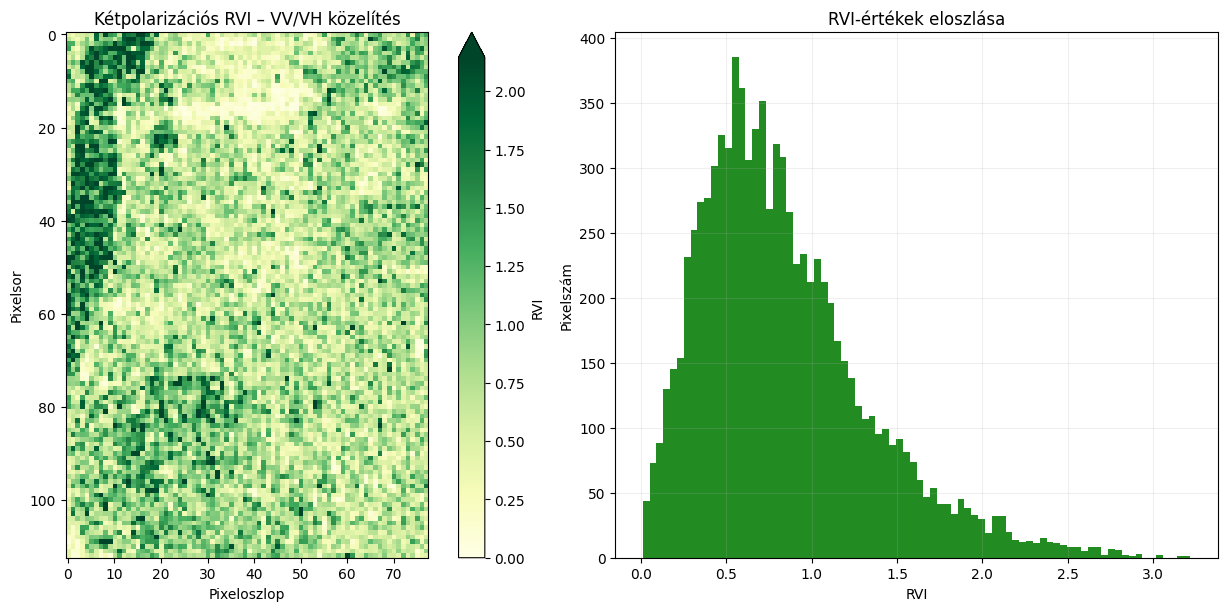

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# Csak akkor legyen True, ha a tömböket már dB-be alakítottad.
INPUT_IS_DB = False

vv = np.ma.masked_invalid(
    np.ma.asarray(gamma0_vv, dtype="float32")
)
vh = np.ma.masked_invalid(
    np.ma.asarray(gamma0_vh, dtype="float32")
)

if vv.shape != vh.shape:
    raise ValueError("A VV és VH kivágás mérete nem egyezik.")

# Szükség esetén visszaalakítás dB-ről lineáris intenzitásra.
if INPUT_IS_DB:
    vv = np.ma.power(10.0, vv / 10.0)
    vh = np.ma.power(10.0, vh / 10.0)

# Közös érvényességi maszk.
denominator = vv + vh

invalid = (
    np.ma.getmaskarray(vv)
    | np.ma.getmaskarray(vh)
    | (vv.filled(-1) < 0)
    | (vh.filled(-1) < 0)
    | (denominator.filled(0) <= 0)
)

vv_valid = np.ma.array(vv, mask=invalid)
vh_valid = np.ma.array(vh, mask=invalid)

# RVI: az érvénytelen/nulla nevezőjű pixelek maszkolva maradnak.
rvi = np.ma.masked_invalid(
    4.0 * vh_valid / (vv_valid + vh_valid)
)

values = rvi.compressed()

if values.size == 0:
    raise ValueError(
        "Nem maradt érvényes pixel. "
        "Ellenőrizd a kivágást, a NoData értékeket és az adatok egységét."
    )

print("Érvényes pixelek:", values.size)
print(f"RVI minimum: {values.min():.3f}")
print(f"RVI medián:  {np.median(values):.3f}")
print(f"RVI maximum: {values.max():.3f}")

# Csak a megjelenítési skála felső határa:
# az eredeti RVI-adatokat nem vágjuk le.
display_max = max(float(np.percentile(values, 98)), 1e-6)

cmap = plt.get_cmap("YlGn").copy()
cmap.set_bad("lightgray")

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

image = axes[0].imshow(
    rvi,
    cmap=cmap,
    vmin=0,
    vmax=display_max,
    origin="upper",
    interpolation="nearest",
)

axes[0].set_title("Kétpolarizációs RVI – VV/VH közelítés")
axes[0].set_xlabel("Pixeloszlop")
axes[0].set_ylabel("Pixelsor")

fig.colorbar(
    image,
    ax=axes[0],
    label="RVI",
    extend="max",
)

axes[1].hist(
    values,
    bins=80,
    color="forestgreen",
    edgecolor="none",
)
axes[1].set_title("RVI-értékek eloszlása")
axes[1].set_xlabel("RVI")
axes[1].set_ylabel("Pixelszám")
axes[1].grid(alpha=0.2)

plt.show()

**Hogyan értelmezd?**

Ennek a konkrét képletnek nemnegatív bemenetek mellett a matematikai tartománya 0–4, nem automatikusan 0–1. Ezért a számított adatokat nem vágjuk le 1-nél.

A magasabb érték nagyobb VH-részarányt jelent a VV+VH összeghez képest; az index a radar-visszaszórás tulajdonságait jellemzi, nem közvetlen növényborítási százalékot.

A térképen a felső 2% telített színnel jelenhet meg a jobb kontraszt érdekében. A hisztogram viszont az összes érvényes számított értéket mutatja.

A cella után az rvi változó már létezik, így a korábban megadott külön RVI-ábrázoló cella is futtatható

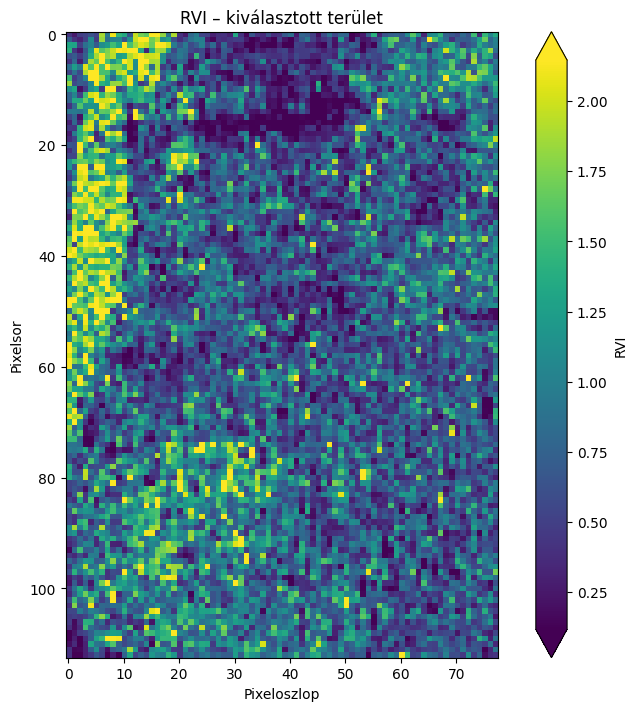

In [58]:
rvi_plot = np.ma.masked_invalid(np.ma.asarray(rvi))

if rvi_plot.count() == 0:
    raise ValueError("Az RVI nem tartalmaz érvényes pixelt.")

lo, hi = np.percentile(rvi_plot.compressed(), [2, 98])
if hi <= lo:
    hi = lo + 1e-6

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")

image = ax.imshow(
    rvi_plot,
    cmap=cmap,
    vmin=lo,
    vmax=hi,
    origin="upper",
    interpolation="nearest",
)

ax.set_title("RVI – kiválasztott terület")
ax.set_xlabel("Pixeloszlop")
ax.set_ylabel("Pixelsor")

fig.colorbar(image, ax=ax, label="RVI", extend="both")
plt.show()